In [2]:
import cv2
import os

os.makedirs("output", exist_ok=True)

frame = None
cap = cv2.VideoCapture(0)

if cap.isOpened():
    print("Press SPACE to capture the image or ESC to exit.")
    while True:
        ret, img = cap.read()
        if not ret:
            break
        cv2.imshow("Webcam", img)
        key = cv2.waitKey(1) & 0xFF
        if key == 32:            # SPACE -> capture the current frame
            frame = img.copy()
            break
        if key == 27:            # ESC -> exit without capturing
            break
    cap.release()
    cv2.destroyAllWindows()
else:
    print("Webcam not found. Loading sample image.")
    frame = cv2.imread("images/sample.jpg")

# Display image details and save it
if frame is not None:
    height, width, channels = frame.shape
    print("Image size:", width, "x", height)
    print("Channels:", channels)
    print("Total pixels:", height * width)

    cv2.imwrite("output/captured.jpg", frame)
    cv2.imwrite("output/captured.png", frame)
    print("Image saved in JPG and PNG formats.")
else:
    print("No image available.")


Press SPACE to capture the image or ESC to exit.
Image size: 640 x 480
Channels: 3
Total pixels: 307200
Image saved in JPG and PNG formats.


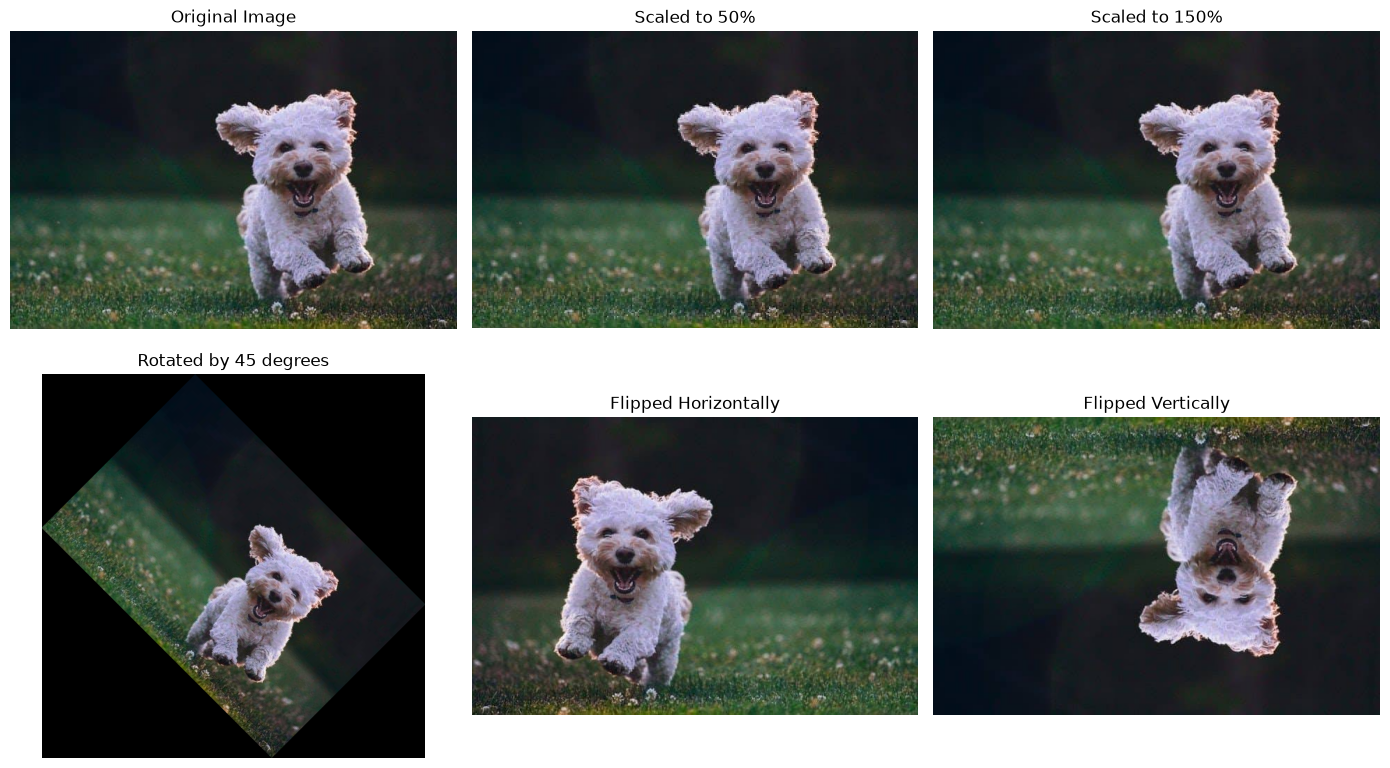

Original size : 640 x 427
Scaled 50%    : 320 x 213
Scaled 150%   : 960 x 640
Rotated 45    : 754 x 754


In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)

image = cv2.imread("images/sample.jpg")
if image is None:
    print("Image not found. Check images/sample.jpg")
    exit()


def scale_image(img, fx, fy):
    """Scaling using nearest-neighbour (inverse) mapping."""
    h, w = img.shape[:2]
    new_h, new_w = int(h * fy), int(w * fx)
    src_y = np.clip((np.arange(new_h) / fy).astype(int), 0, h - 1)
    src_x = np.clip((np.arange(new_w) / fx).astype(int), 0, w - 1)
    return img[src_y[:, None], src_x[None, :]]


def rotate_image(img, angle):
    """Rotation about the centre; the canvas grows so nothing is cut off."""
    h, w = img.shape[:2]
    a = np.deg2rad(angle)
    cos, sin = np.cos(a), np.sin(a)
    new_w = int(abs(w * cos) + abs(h * sin))
    new_h = int(abs(w * sin) + abs(h * cos))
    out = np.zeros((new_h, new_w, 3), dtype=np.uint8)

    # Every output pixel is traced back to its source pixel
    ys, xs = np.indices((new_h, new_w))
    xr, yr = xs - new_w / 2, ys - new_h / 2
    src_x = np.round(xr * cos + yr * sin + w / 2).astype(int)
    src_y = np.round(-xr * sin + yr * cos + h / 2).astype(int)

    valid = (src_x >= 0) & (src_x < w) & (src_y >= 0) & (src_y < h)
    out[valid] = img[src_y[valid], src_x[valid]]
    return out


def flip_horizontal(img):
    w = img.shape[1]
    cols = np.arange(w - 1, -1, -1)          # w-1, w-2, ..., 0
    return img[:, cols]


def flip_vertical(img):
    h = img.shape[0]
    rows = np.arange(h - 1, -1, -1)
    return img[rows, :]


scaled_down = scale_image(image, 0.5, 0.5)
scaled_up = scale_image(image, 1.5, 1.5)
rotated = rotate_image(image, 45)
flip_h = flip_horizontal(image)
flip_v = flip_vertical(image)

cv2.imwrite("output/scaled_50.jpg", scaled_down)
cv2.imwrite("output/scaled_150.jpg", scaled_up)
cv2.imwrite("output/rotated_45.jpg", rotated)
cv2.imwrite("output/flipped_horizontal.jpg", flip_h)
cv2.imwrite("output/flipped_vertical.jpg", flip_v)

results = [
    ("Original Image", image),
    ("Scaled to 50%", scaled_down),
    ("Scaled to 150%", scaled_up),
    ("Rotated by 45 degrees", rotated),
    ("Flipped Horizontally", flip_h),
    ("Flipped Vertically", flip_v),
]

plt.figure(figsize=(14, 8))
for i, (title, img) in enumerate(results, start=1):
    plt.subplot(2, 3, i)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.savefig("output/exp02_result.png")
plt.show()

print("Original size :", image.shape[1], "x", image.shape[0])
print("Scaled 50%    :", scaled_down.shape[1], "x", scaled_down.shape[0])
print("Scaled 150%   :", scaled_up.shape[1], "x", scaled_up.shape[0])
print("Rotated 45    :", rotated.shape[1], "x", rotated.shape[0])



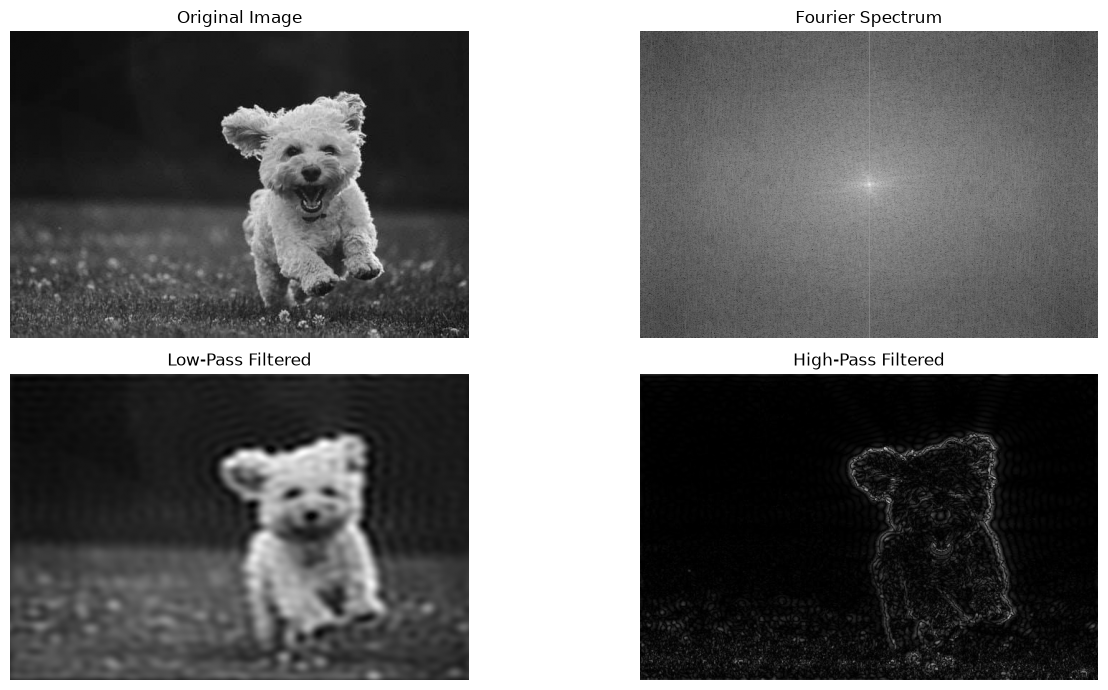

Cut-off radius: 30
Low-pass image saved to output/low_pass.jpg
High-pass image saved to output/high_pass.jpg


In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)

image = cv2.imread("images/sample.jpg", cv2.IMREAD_GRAYSCALE)
if image is None:
    print("Image not found. Check images/sample.jpg")
    exit()

# Fourier transform with the zero frequency shifted to the centre
fourier = np.fft.fftshift(np.fft.fft2(image))
spectrum = np.log1p(np.abs(fourier))

# Circular masks around the centre
height, width = image.shape
y, x = np.ogrid[:height, :width]
distance = np.sqrt((x - width // 2) ** 2 + (y - height // 2) ** 2)

radius = 30
low_mask = (distance <= radius).astype(np.float32)    # keeps low frequencies
high_mask = 1 - low_mask                              # keeps high frequencies


def back_to_image(filtered):
    """Inverse FFT followed by scaling to the range 0-255."""
    img = np.abs(np.fft.ifft2(np.fft.ifftshift(filtered)))
    return cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)


low_image = back_to_image(fourier * low_mask)
high_image = back_to_image(fourier * high_mask)

cv2.imwrite("output/low_pass.jpg", low_image)
cv2.imwrite("output/high_pass.jpg", high_image)

plt.figure(figsize=(14, 7))
titles = ["Original Image", "Fourier Spectrum",
          "Low-Pass Filtered", "High-Pass Filtered"]
images = [image, spectrum, low_image, high_image]
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.savefig("output/exp04_result.png")
plt.show()

print("Cut-off radius:", radius)
print("Low-pass image saved to output/low_pass.jpg")
print("High-pass image saved to output/high_pass.jpg")


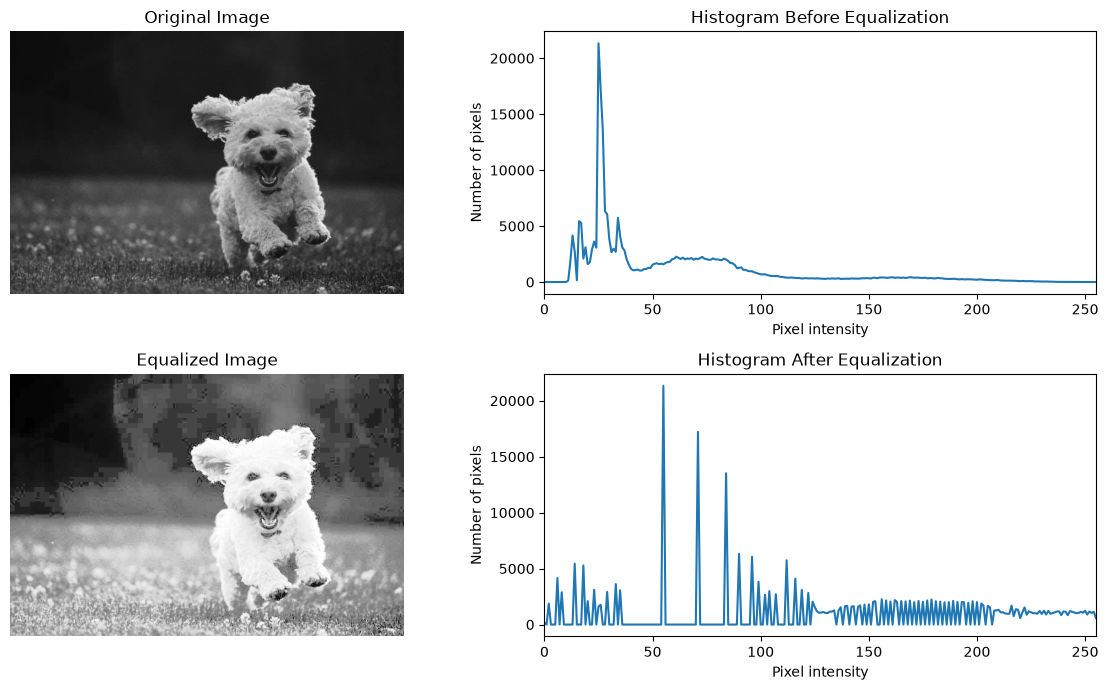

Intensity range before: 0 - 255
Intensity range after : 0 - 255


In [2]:
import cv2
import matplotlib.pyplot as plt
import os

os.makedirs("output", exist_ok=True)

image = cv2.imread("images/sample.jpg", cv2.IMREAD_GRAYSCALE)
if image is None:
    print("Image not found. Check images/sample.jpg")
    exit()

# Histogram equalization
equalized = cv2.equalizeHist(image)
cv2.imwrite("output/equalized.jpg", equalized)

# Histograms (256 bins, values 0-255)
hist_before = cv2.calcHist([image], [0], None, [256], [0, 256])
hist_after = cv2.calcHist([equalized], [0], None, [256], [0, 256])

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.plot(hist_before)
plt.title("Histogram Before Equalization")
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.xlim([0, 255])

plt.subplot(2, 2, 3)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.plot(hist_after)
plt.title("Histogram After Equalization")
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.xlim([0, 255])

plt.tight_layout()
plt.savefig("output/exp05_result.png")
plt.show()

print("Intensity range before:", image.min(), "-", image.max())
print("Intensity range after :", equalized.min(), "-", equalized.max())


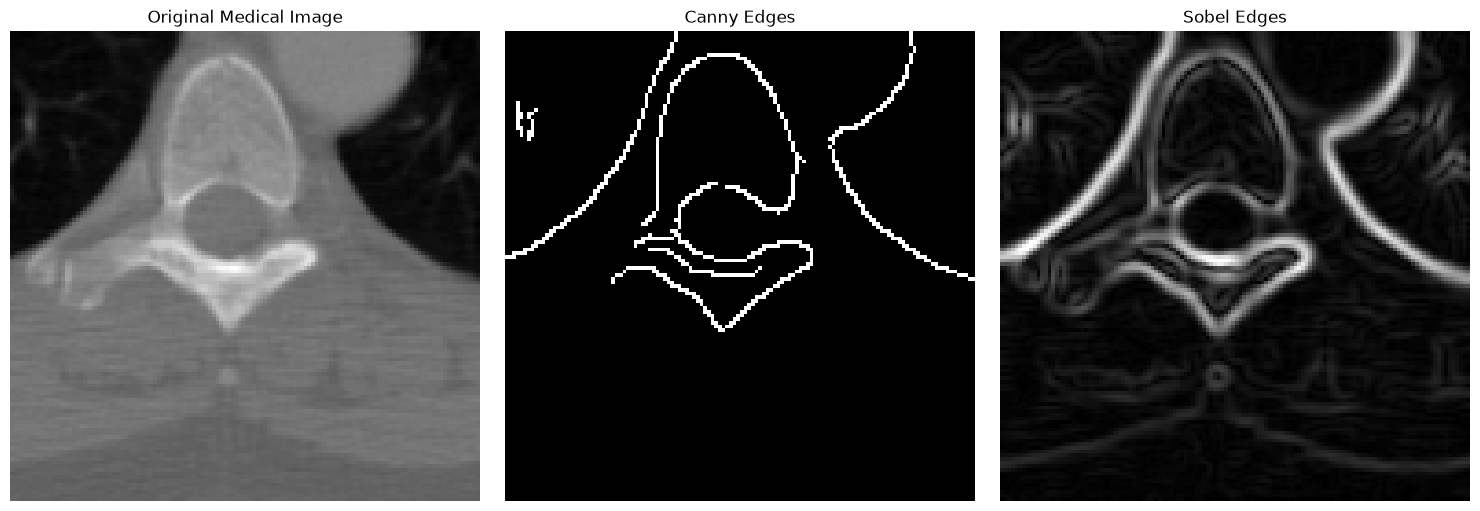

Image size: 128 x 128
Canny thresholds: 73 147
Edge pixels (Canny): 609


In [9]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)

filename = "images/medical.dcm"      # a .jpg/.png export of a scan also works


def load_medical_image(path):
    """Reads a DICOM (or ordinary image) file and returns an 8-bit grayscale image."""
    if path.lower().endswith(".dcm"):
        import pydicom
        data = pydicom.dcmread(path)
        img = data.pixel_array.astype(np.float32)
        img = img * float(getattr(data, "RescaleSlope", 1)) \
                  + float(getattr(data, "RescaleIntercept", 0))
        if img.ndim == 3:                       # colour or multi-frame file
            img = img.mean(axis=2) if img.shape[2] == 3 else img[img.shape[0] // 2]
    else:
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            return None
        img = img.astype(np.float32)
    return cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)


image = load_medical_image(filename)
if image is None:
    print("Could not read the medical image:", filename)
    exit()

# Remove noise before detecting edges
blurred = cv2.GaussianBlur(image, (5, 5), 0)

# Canny with thresholds chosen automatically from the median intensity
median = np.median(blurred)
lower = int(max(0, 0.66 * median))
upper = int(min(255, 1.33 * median))
canny = cv2.Canny(blurred, lower, upper)

# Sobel gradient magnitude for comparison
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))

cv2.imwrite("output/medical_canny.jpg", canny)
cv2.imwrite("output/medical_sobel.jpg", sobel)

plt.figure(figsize=(15, 5))
for i, (title, img) in enumerate([("Original Medical Image", image),
                                  ("Canny Edges", canny),
                                  ("Sobel Edges", sobel)], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.savefig("output/exp06_result.png")
plt.show()

print("Image size:", image.shape[1], "x", image.shape[0])
print("Canny thresholds:", lower, upper)
print("Edge pixels (Canny):", int(np.count_nonzero(canny)))


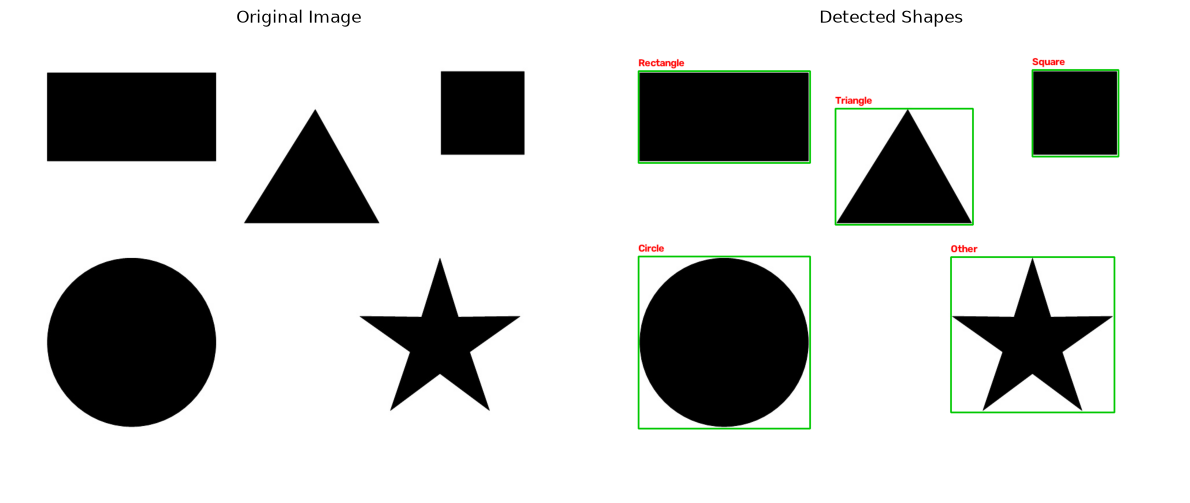

Shapes found: {'Other': 1, 'Circle': 1, 'Triangle': 1, 'Rectangle': 1, 'Square': 1}
Output saved to output/shapes_detected.jpg


In [10]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)

image = cv2.imread("images/shapes.jpg")
if image is None:
    print("Image not found. Check images/shapes.jpg")
    exit()

output = image.copy()
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Edges are thickened so that outlines (and thin lines) form closed regions
edges = cv2.Canny(blurred, 50, 150)
edges = cv2.dilate(edges, np.ones((3, 3), np.uint8), iterations=2)
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

counts = {}

for contour in contours:
    perimeter = cv2.arcLength(contour, True)
    if perimeter < 60:                       # ignore noise
        continue

    area = cv2.contourArea(contour)
    (cx, cy), (rw, rh), angle = cv2.minAreaRect(contour)
    short_side, long_side = min(rw, rh), max(rw, rh)
    ratio = short_side / long_side if long_side > 0 else 0

    approx = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
    corners = len(approx)
    circularity = 4 * np.pi * area / (perimeter ** 2)

    if ratio < 0.2:
        shape = "Line"
    elif corners == 3:
        shape = "Triangle"
    elif corners == 4:
        shape = "Square" if ratio > 0.9 else "Rectangle"
    elif circularity > 0.8:
        shape = "Circle"
    else:
        shape = "Other"

    counts[shape] = counts.get(shape, 0) + 1

    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(output, (x, y), (x + w, y + h), (0, 200, 0), 2)
    cv2.putText(output, shape, (x, max(y - 8, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

cv2.imwrite("output/shapes_detected.jpg", output)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Detected Shapes")
plt.axis("off")
plt.tight_layout()
plt.savefig("output/exp07_result.png")
plt.show()

print("Shapes found:", counts)
print("Output saved to output/shapes_detected.jpg")


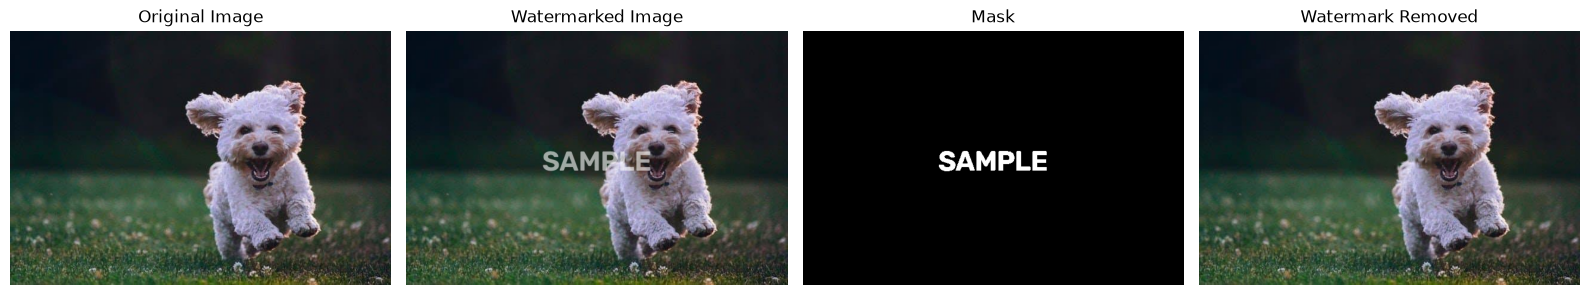

PSNR (original vs watermarked): 26.26 dB
PSNR (original vs restored)   : 42.72 dB
Watermarked image saved to output/watermarked.jpg
Restored image saved to output/restored.jpg


In [11]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

os.makedirs("output", exist_ok=True)

image = cv2.imread("images/sample.jpg")
if image is None:
    print("Image not found. Check images/sample.jpg")
    exit()

height, width = image.shape[:2]
text = "SAMPLE"
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = width / 400
thickness = max(2, int(font_scale * 2))

# Centre the watermark text
(text_w, text_h), baseline = cv2.getTextSize(text, font, font_scale, thickness)
position = ((width - text_w) // 2, (height + text_h) // 2)

# Add a semi-transparent white watermark
overlay = image.copy()
cv2.putText(overlay, text, position, font, font_scale,
            (255, 255, 255), thickness, cv2.LINE_AA)
watermarked = cv2.addWeighted(overlay, 0.6, image, 0.4, 0)
cv2.imwrite("output/watermarked.jpg", watermarked)

# Mask: white where the watermark lies (slightly thicker than the text)
mask = np.zeros((height, width), dtype=np.uint8)
cv2.putText(mask, text, position, font, font_scale, 255, thickness + 4, cv2.LINE_AA)
_, mask = cv2.threshold(mask, 10, 255, cv2.THRESH_BINARY)

# Remove the watermark using inpainting
restored = cv2.inpaint(watermarked, mask, 3, cv2.INPAINT_TELEA)
cv2.imwrite("output/mask.png", mask)
cv2.imwrite("output/restored.jpg", restored)

plt.figure(figsize=(16, 6))
for i, (title, img) in enumerate([("Original Image", image),
                                  ("Watermarked Image", watermarked),
                                  ("Mask", mask),
                                  ("Watermark Removed", restored)], start=1):
    plt.subplot(1, 4, i)
    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.savefig("output/exp08_result.png")
plt.show()

print("PSNR (original vs watermarked): %.2f dB" % cv2.PSNR(image, watermarked))
print("PSNR (original vs restored)   : %.2f dB" % cv2.PSNR(image, restored))
print("Watermarked image saved to output/watermarked.jpg")
print("Restored image saved to output/restored.jpg")



In [ ]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

os.makedirs("output/characters", exist_ok=True)

image = cv2.imread("images/text.jpg", cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Image not found. Check images/text.jpg")
    exit()

# Text becomes white on a black background
_, binary = cv2.threshold(
    image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Detect contours
contours, _ = cv2.findContours(
    binary, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
)

# Filter character candidates
boxes = []

for c in contours:
    area = cv2.contourArea(c)
    x, y, w, h = cv2.boundingRect(c)

    if area > 300 and 20 < w < 150 and 20 < h < 150:
        boxes.append((x, y, w, h))

print("Character candidates:", len(boxes))

if len(boxes) == 0:
    print("No characters detected. Check image preprocessing.")
    exit()

# Group boxes into text lines
boxes.sort(key=lambda b: b[1] + b[3] / 2)

median_height = np.median([b[3] for b in boxes])

lines, current = [], [boxes[0]]

for box in boxes[1:]:
    previous_centre = np.mean(
        [b[1] + b[3] / 2 for b in current]
    )

    if (box[1] + box[3] / 2) - previous_centre > 0.6 * median_height:
        lines.append(current)
        current = []

    current.append(box)

lines.append(current)

# Sort characters from left to right
characters = [
    b for line in lines
    for b in sorted(line, key=lambda b: b[0])
]

# Save individual characters
segmented = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
pad = 2

for index, (x, y, w, h) in enumerate(characters, start=1):

    crop = image[
        max(y - pad, 0):y + h + pad,
        max(x - pad, 0):x + w + pad
    ]

    cv2.imwrite(
        f"output/characters/char_{index:03d}.png", crop
    )

    cv2.rectangle(
        segmented, (x, y), (x + w, y + h), (0, 200, 0), 2
    )

cv2.imwrite("output/segmented_text.jpg", segmented)

# Display results
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Text Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(segmented, cv2.COLOR_BGR2RGB))
plt.title("Character Segmentation")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/exp09_result.png")
plt.show()

detected = len(characters)

print("Text lines found:", len(lines))
print("Characters detected:", detected)
print("Individual character images saved in output/characters/")

# Accuracy against manually counted reference
expected = int(input("Enter the actual number of characters: "))

if expected > 0:
    accuracy = max(
        0.0, 1 - abs(detected - expected) / expected
    ) * 100

    print(f"Segmentation accuracy: {accuracy:.2f}%")
else:
    print("Accuracy cannot be calculated.")


Image not found. Check images/text.jpg


c:\study material\ML Course\venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\study material\ML Course\venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


IndexError: list index out of range

: 

In [ ]:
import cv2
import time

image = cv2.imread("images/boxes.jpg")
if image is None:
    print("Image not found. Check images/boxes.jpg")
    exit()

start = time.perf_counter()

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Dark box outlines and dark filled boxes become white
_, binary = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

filled = 0
empty = 0

for contour in contours:
    area = cv2.contourArea(contour)
    if area < 400:                              # ignore noise
        continue

    x, y, w, h = cv2.boundingRect(contour)
    perimeter = cv2.arcLength(contour, True)
    approx = cv2.approxPolyDP(contour, 0.04 * perimeter, True)

    # Accept only four-cornered shapes that fill their bounding rectangle
    if len(approx) != 4 or area / float(w * h) < 0.85:
        continue

    # Look at the central part of the box (works for any box size)
    mx, my = int(0.25 * w), int(0.25 * h)
    inner = binary[y + my:y + h - my, x + mx:x + w - mx]
    fill_ratio = cv2.countNonZero(inner) / float(inner.size)

    if fill_ratio > 0.5:
        filled += 1
        label, colour = "Filled", (0, 0, 255)
    else:
        empty += 1
        label, colour = "Empty", (255, 0, 0)

    cv2.rectangle(image, (x, y), (x + w, y + h), colour, 2)
    cv2.putText(image, label, (x, max(y - 6, 12)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, colour, 1)

elapsed = time.perf_counter() - start
print("Filled boxes:", filled)
print("Empty boxes:", empty)
print(f"Execution time: {elapsed:.4f} seconds")

# Compare with manually counted reference values
actual_filled = int(input("Enter the actual number of filled boxes: "))
actual_empty = int(input("Enter the actual number of empty boxes: "))
actual_total = actual_filled + actual_empty
detected_total = filled + empty

if actual_total > 0:
    correct = min(filled, actual_filled) + min(empty, actual_empty)
    accuracy = correct / max(actual_total, detected_total) * 100
    print(f"Count accuracy: {accuracy:.2f}%")
    print(f"Efficiency: {detected_total / elapsed:.1f} boxes per second")
else:
    print("Accuracy cannot be calculated.")

cv2.imwrite("output/boxes_detected.jpg", image)
cv2.imshow("Box Detection", image)
cv2.waitKey(0)
cv2.destroyAllWindows()
